# Video game sales: regional demand and platform history

Which games and genres account for the recorded sales, and do regional preferences differ? The analysis compares sales volume with the number of releases so that a large catalogue is not automatically treated as strong sales per release.

## Data and scope

Source: [videogamesales](https://www.kaggle.com/datasets/gregorut/videogamesales). This report uses the uploaded snapshot, not live data.

Each row is a game-platform release. `Name`, `Platform`, `Genre` and `Publisher` identify it; `Year` is the release year. `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales` and `Global_Sales` are recorded sales in millions of units. `Rank` is the supplied sales rank. The same title on two platforms is two releases, so title names alone are not a duplicate key.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("vgsales.csv"))
print(f"Raw data: {raw.shape[0]:,} rows and {raw.shape[1]} columns")
assert raw.shape[0] >= 150 and raw.shape[1] >= 3
display(raw.head())
display(raw.isna().sum().rename("missing").to_frame())

Raw data: 16,598 rows and 11 columns


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,"2,006.000",Sports,Nintendo,41.490,29.020,3.770,8.460,82.740
1,2,Super Mario Bros.,NES,"1,985.000",Platform,Nintendo,29.080,3.580,6.810,0.770,40.240
2,3,Mario Kart Wii,Wii,"2,008.000",Racing,Nintendo,15.850,12.880,3.790,3.310,35.820
3,4,Wii Sports Resort,Wii,"2,009.000",Sports,Nintendo,15.750,11.010,3.280,2.960,33.000
4,5,Pokemon Red/Pokemon Blue,GB,"1,996.000",Role-Playing,Nintendo,11.270,8.890,10.220,1.000,31.370


,missing
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


## Cleaning and first checks

`duplicated()` checks exact repeated rows. Text is stripped of surrounding spaces. Missing release years stay missing; filling them with an average year would invent a release date. Unknown publishers are labelled explicitly. Sales below zero would be invalid and are changed to missing. `describe()` gives counts, averages, quartiles and ranges; the median is useful because a few very large releases can pull up the mean.

Exact duplicates removed: 0; missing years: 271
Largest absolute difference between regional sum and global sales: 0.020 million


,count,mean,std,min,25%,50%,75%,max
NA_Sales,"16,598.000",0.265,0.817,0.000,0.000,0.080,0.240,41.490
EU_Sales,"16,598.000",0.147,0.505,0.000,0.000,0.020,0.110,29.020
JP_Sales,"16,598.000",0.078,0.309,0.000,0.000,0.000,0.040,10.220
Other_Sales,"16,598.000",0.048,0.189,0.000,0.000,0.010,0.040,10.570
Global_Sales,"16,598.000",0.537,1.555,0.010,0.060,0.170,0.470,82.740


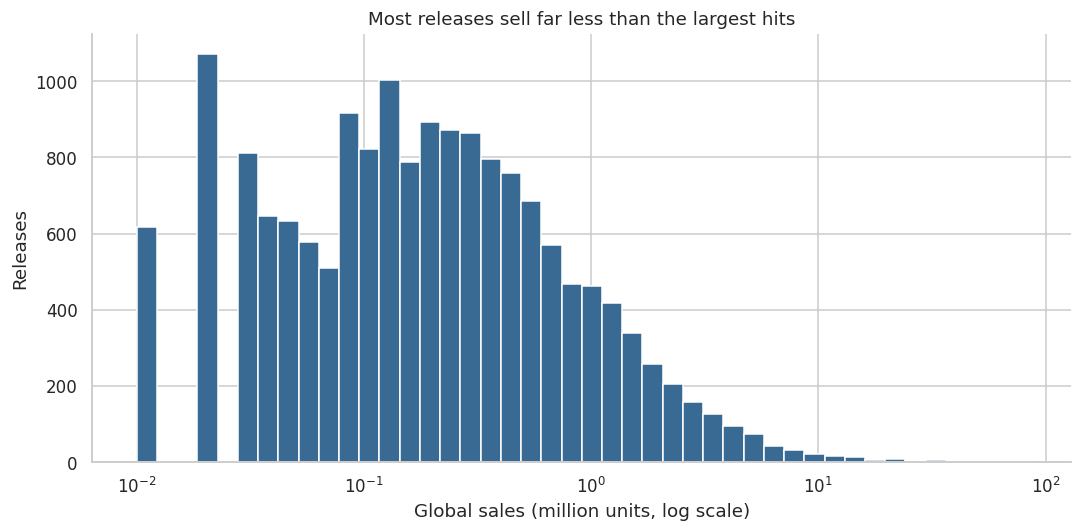

In [3]:
df = raw.drop_duplicates().copy()
for col in ["Name", "Platform", "Genre", "Publisher"]:
    df[col] = df[col].astype("string").str.strip().replace("", pd.NA)
df["Publisher"] = df["Publisher"].fillna("Unknown")
df["Year"] = pd.to_numeric(df["Year"], errors="coerce").astype("Int64")
sales = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
for col in sales:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col] < 0, col] = np.nan
print(f"Exact duplicates removed: {len(raw)-len(df):,}; missing years: {df.Year.isna().sum():,}")
display(df[sales].describe().T)
residual = df[sales[:-1]].sum(axis=1, min_count=4) - df.Global_Sales
print(f"Largest absolute difference between regional sum and global sales: {residual.abs().max():.3f} million")
fig, ax = plt.subplots()
ax.hist(df.Global_Sales.dropna(), bins=np.geomspace(0.01, df.Global_Sales.max()+0.01, 45), color="#386a93")
ax.set(xscale="log", xlabel="Global sales (million units, log scale)", ylabel="Releases", title="Most releases sell far less than the largest hits")
plt.tight_layout(); plt.show()

## 1. Which genres lead in total sales and sales per release?

`groupby()` collects releases by genre. `agg()` calculates totals, medians and release counts together. The median describes a typical recorded release; it need not rank genres in the same order as total sales.

,releases,total_million,median_million,mean_million
Genre,,,,
Action,3316,"1,751.180",0.190,0.528
Sports,2346,"1,330.930",0.220,0.567
Shooter,1310,"1,037.370",0.230,0.792
Role-Playing,1488,927.370,0.185,0.623
Platform,886,831.370,0.280,0.938
Misc,1739,809.960,0.160,0.466
Racing,1249,732.040,0.190,0.586
Fighting,848,448.910,0.210,0.529
Simulation,867,392.200,0.160,0.452


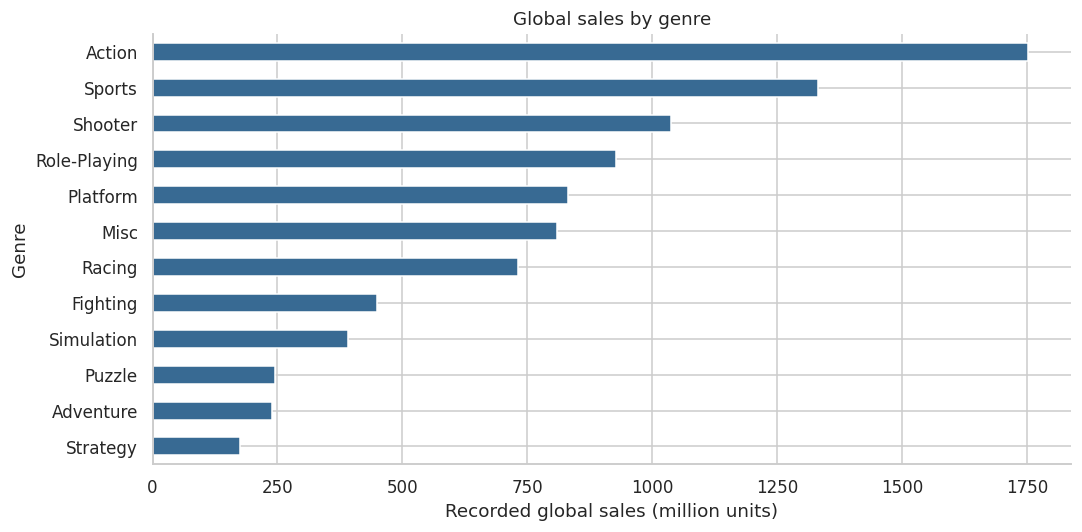

In [4]:
genre = df.groupby("Genre").agg(releases=("Name","size"), total_million=("Global_Sales","sum"), median_million=("Global_Sales","median"), mean_million=("Global_Sales","mean")).sort_values("total_million",ascending=False)
display(genre)
genre.total_million.sort_values().plot.barh(color="#386a93")
plt.xlabel("Recorded global sales (million units)"); plt.ylabel("Genre")
plt.title("Global sales by genre"); plt.tight_layout(); plt.show()

**Answer.** Action leads in total sales with 1,751.18 million units across 3,316 releases. Platform has the highest median sales per release (0.28 million). The difference matters: a genre can lead overall partly because it has many recorded releases.

## 2. Do North America, Europe and Japan favour the same genres?

Regional totals are divided by each region’s total using `div()`. This produces comparable percentages rather than letting the largest regional market dominate the chart. These are shares within the supplied dataset.

,NA_Sales,EU_Sales,JP_Sales
Genre,,,
Action,19.980,21.570,12.390
Adventure,2.410,2.630,4.030
Fighting,5.090,4.160,6.770
Misc,9.340,8.870,8.350
Platform,10.180,8.280,10.130
Puzzle,2.820,2.090,4.440
Racing,8.180,9.790,4.390
Role-Playing,7.450,7.730,27.290
Shooter,13.260,12.870,2.970


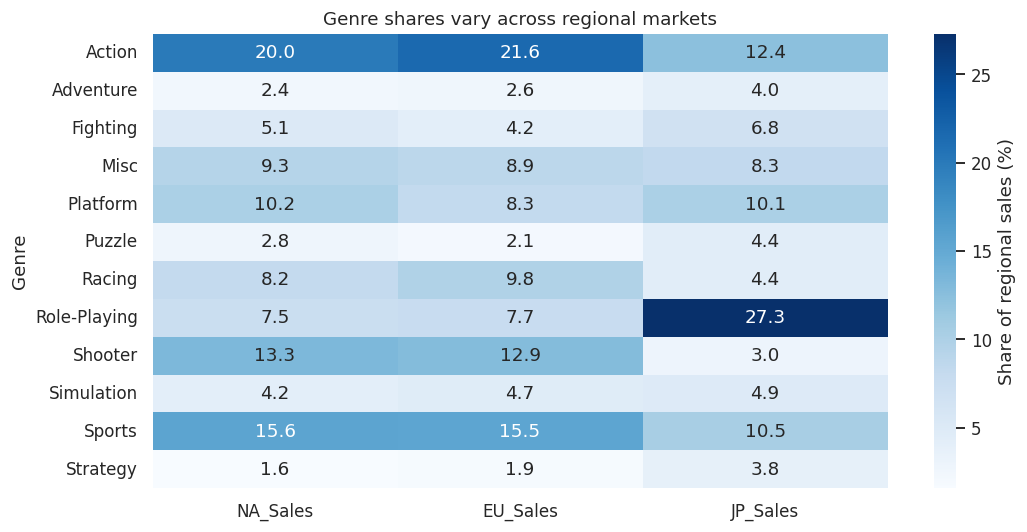

In [5]:
regional = df.groupby("Genre")[["NA_Sales","EU_Sales","JP_Sales"]].sum()
shares = regional.div(regional.sum(), axis=1).mul(100)
display(shares.round(2))
sns.heatmap(shares, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label":"Share of regional sales (%)"})
plt.title("Genre shares vary across regional markets"); plt.ylabel("Genre"); plt.tight_layout(); plt.show()

**Answer.** The leading genres are Action in North America (20.0%), Action in Europe (21.6%), and Role-Playing in Japan (27.3%). A single global ranking therefore loses some useful regional detail.

## 3. Which platforms account for the most recorded sales?

`sort_values()` orders platform totals. The chart shows the ten largest platforms, while the table also reports their release counts and median sales. It compares accumulated platform histories, not annual market shares.

,sales_million,releases,median_million
Platform,,,
PS2,"1,255.640",2161,0.230
X360,979.960,1265,0.280
PS3,957.840,1329,0.280
Wii,926.710,1325,0.200
DS,822.490,2163,0.110
PS,730.660,1196,0.260
GBA,318.500,822,0.165
PSP,296.280,1213,0.090
PS4,278.100,336,0.220


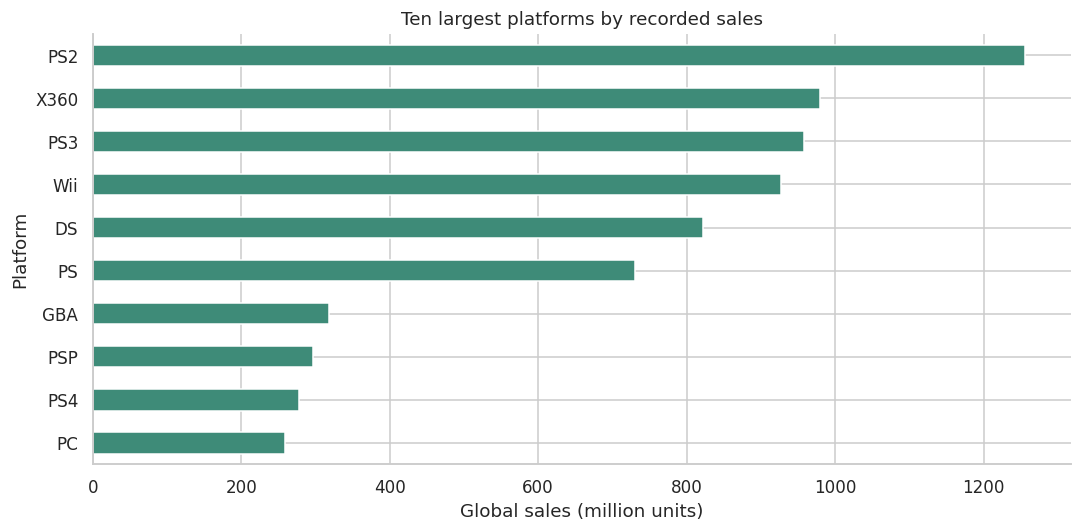

In [6]:
platform = df.groupby("Platform").agg(sales_million=("Global_Sales","sum"), releases=("Name","size"), median_million=("Global_Sales","median")).sort_values("sales_million",ascending=False)
display(platform.head(10))
platform.sales_million.head(10).sort_values().plot.barh(color="#3e8b78")
plt.xlabel("Global sales (million units)"); plt.title("Ten largest platforms by recorded sales"); plt.tight_layout(); plt.show()

**Answer.** PS2 has the largest recorded platform total, 1,255.64 million units. Its 2,161 releases have a median of 0.23 million units. Platform age and catalogue size both affect this lifetime comparison.

## 4. Which release years have the highest recorded sales?

Rows with missing years are excluded only from this question. Sales are grouped by release year, so the result describes the lifetime sales of releases from that year, not sales transactions made during that year. Later years may have incomplete coverage.

,sales_million,releases
Year,,
2008,678.900,1428
2009,667.300,1431
2007,611.130,1202
2010,600.450,1259
2006,521.040,1008
2011,515.990,1139
2005,459.940,941
2004,419.310,763


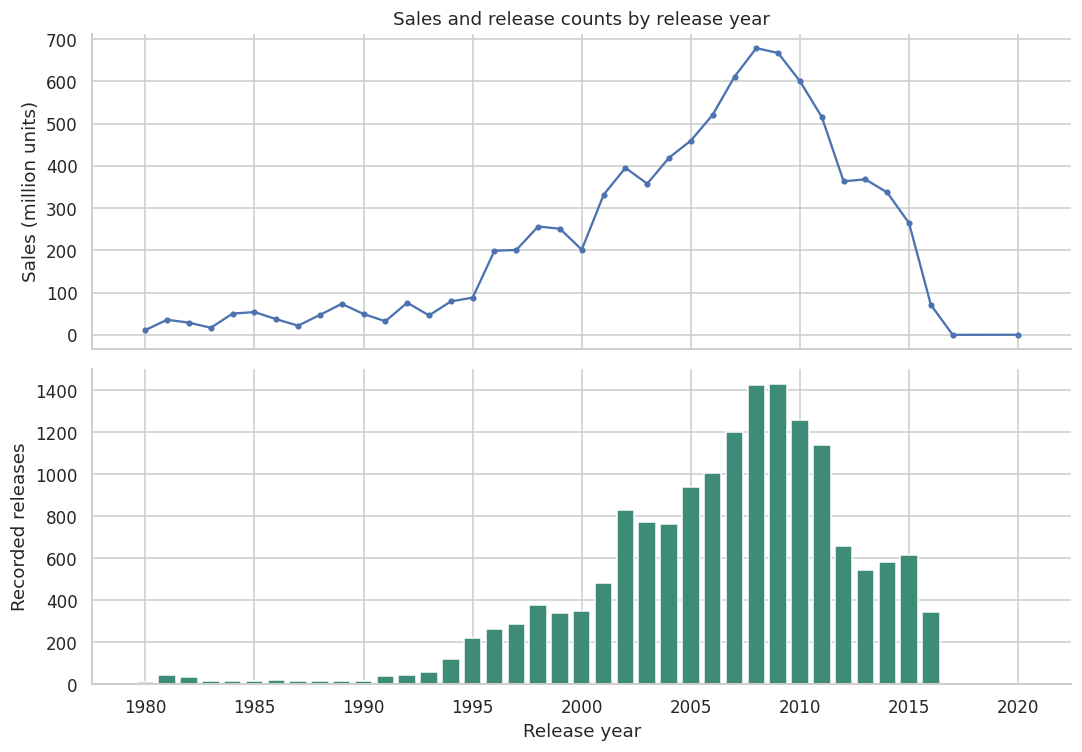

In [7]:
yearly = df.dropna(subset=["Year"]).groupby("Year").agg(sales_million=("Global_Sales","sum"), releases=("Name","size"))
display(yearly.sort_values("sales_million",ascending=False).head(8))
fig, axes = plt.subplots(2,1,figsize=(10,7),sharex=True)
axes[0].plot(yearly.index,yearly.sales_million,marker=".")
axes[0].set(ylabel="Sales (million units)",title="Sales and release counts by release year")
axes[1].bar(yearly.index,yearly.releases,color="#3e8b78")
axes[1].set(xlabel="Release year",ylabel="Recorded releases")
plt.tight_layout(); plt.show()

**Answer.** Releases from 2008 have the highest recorded sales total (678.90 million units). The most releases occur in 2009. The apparent decline near the end of the file should not be read as evidence that the whole games industry declined.

## 5. How much of the recorded market belongs to the biggest hits?

`nlargest()` selects the biggest game-platform releases. Comparing their sales with the full total puts famous hits in context. A title released on several platforms can appear more than once in this calculation.

,Name,Platform,Year,Global_Sales
0,Wii Sports,Wii,2006,82.740
1,Super Mario Bros.,NES,1985,40.240
2,Mario Kart Wii,Wii,2008,35.820
3,Wii Sports Resort,Wii,2009,33.000
4,Pokemon Red/Pokemon Blue,GB,1996,31.370
5,Tetris,GB,1989,30.260
6,New Super Mario Bros.,DS,2006,30.010
7,Wii Play,Wii,2006,29.020
8,New Super Mario Bros. Wii,Wii,2009,28.620
9,Duck Hunt,NES,1984,28.310


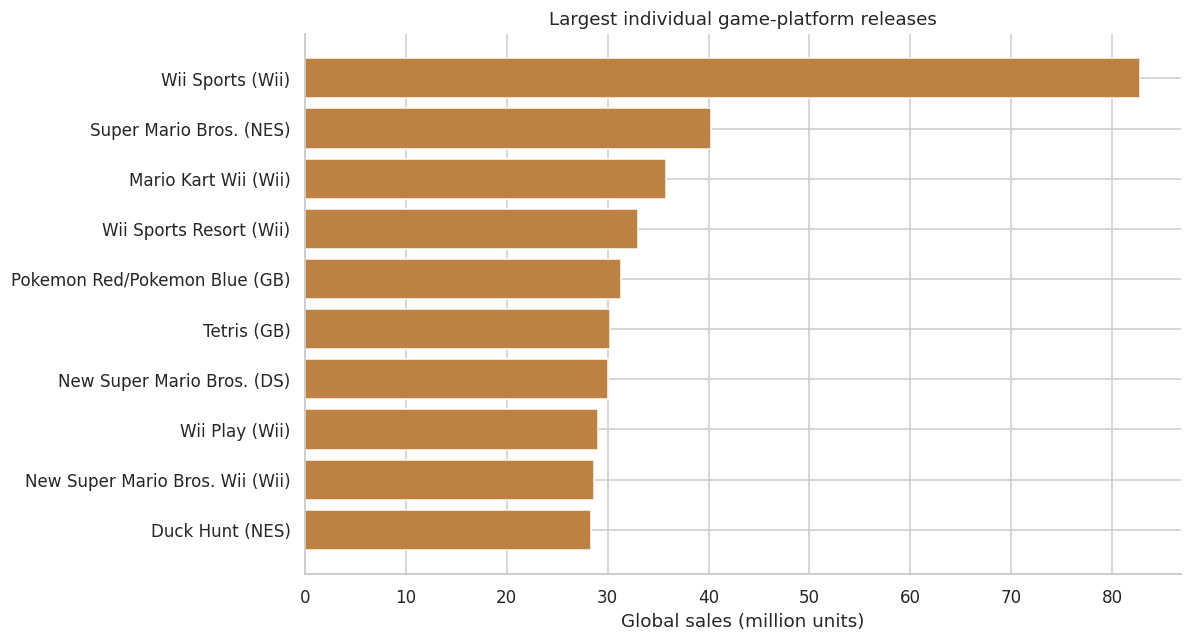

In [8]:
top = df.nlargest(10,"Global_Sales")
top_share = top.Global_Sales.sum()/df.Global_Sales.sum()*100
display(top[["Name","Platform","Year","Global_Sales"]])
labels = top.Name.astype(str)+" ("+top.Platform.astype(str)+")"
fig, ax = plt.subplots(figsize=(11,6))
ax.barh(labels.iloc[::-1],top.Global_Sales.iloc[::-1],color="#bd8242")
ax.set(xlabel="Global sales (million units)",title="Largest individual game-platform releases")
plt.tight_layout(); plt.show()

**Answer.** The ten largest releases account for 4.14% of all recorded global sales. Wii Sports on Wii is first at 82.74 million units. Individual hits are large, but the remaining catalogue still contributes most of the recorded volume.